# Marine heatwave projections

Marine-heatwave (MHW) days per year (all categories, Hobday et al. 2018) from the CMIP6 MHW statistics of Holbrook et al. for SSP1-2.6 and SSP5-8.5, averaged over each Pacific EEZ and over all the EEZs together on every model's native ocean grid; the box plots show the spread across models for the all-EEZ mean. The model domain ends at 15°N, so EEZs further north are only partly covered (or not at all: hatched EEZs).

```{glue:figure} mhw_fig
:scale: 60%
:align: center
```

**Figure. MHW days per year in each Pacific EEZ at the global warming levels** (multi-model median, SSP5-8.5).

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

## Setup

Regional helpers come from `functions/projections_regional.py` (EEZ and all-EEZ means, maps, box plots) and `functions/projections.py` (data access, warming levels); the box plots use `ind_setup.plotting_projections` from the [indicators_setup](https://github.com/lauracagigal/indicators_setup) repository.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from myst_nb import glue

sys.path.append("../../../../../../indicators_setup")
sys.path.append("../../../../functions")
import projections as prj
import projections_regional as reg

### Configuration

Scenarios and global warming levels are the ones of the national projections ([`../../National/00_warming_levels.ipynb`](../../National/00_warming_levels.ipynb)). Maps of the change at warming levels are drawn for every scenario on a shared colour scale (`map_scenario` is the one shown at the top of the notebook); box plots show every scenario. Figures go to `outputs/figures/regional_pacific/PRJ_*` and tables to `outputs/tables/regional_pacific/PRJ_*`.

In [3]:
ssp_scenarios = ['ssp126', 'ssp585']
map_scenario = "ssp585"
scenario_info = prj.load_warming_levels(ssp_scenarios)

eez = reg.load_eez()
fig_dir = Path("../../../../outputs/figures/regional_pacific")
tables_dir = Path("../../../../outputs/tables/regional_pacific")
fig_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

## MHW days per year

Values are the MHW days themselves (not a change), because the historical baseline is close to zero days per year.

**Marine heatwave days: linear trend 2015–2100 of the multi-model median (days/year per decade), by EEZ**

,SSP126,SSP585
American Samoa,18.99,34.86
Cook Islands,17.26,37.05
Fiji,14.01,39.77
French Polynesia,12.91,41.17
Hawaii,NaN,NaN
Howland Island and Baker Island,16.26,45.85
Jarvis Island,15.64,45.70
Johnston Atoll,21.82,35.39
Kiribati,18.07,42.66
Line Group,19.04,41.43


**Marine heatwave days at the global warming levels (SSP126, multi-model median, days/year), by EEZ**

,+1.5°C (2032)
region,
American Samoa,166.1
Cook Islands,154.8
Fiji,112.6
French Polynesia,115.9
Hawaii,NaN
Howland Island and Baker Island,115.5
Jarvis Island,111.7
Johnston Atoll,216.1
Kiribati,150.2


**Marine heatwave days at the global warming levels (SSP585, multi-model median, days/year), by EEZ**

,+1.5°C (2027),+2.0°C (2041),+2.5°C (2053),+3.0°C (2064)
region,,,,
American Samoa,132.9,288.6,317.0,358.4
Cook Islands,151.6,259.6,295.9,350.1
Fiji,105.9,229.1,268.9,347.8
French Polynesia,117.2,216.7,263.9,320.9
Hawaii,NaN,NaN,NaN,NaN
Howland Island and Baker Island,112.7,117.0,267.1,260.7
Jarvis Island,80.8,130.2,244.9,262.8
Johnston Atoll,148.1,339.2,358.1,365.5
Kiribati,138.3,161.7,277.3,295.6


**Marine heatwave days at the global warming levels (days/year): spread across models in All Pacific EEZs**

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,All Pacific EEZs,SSP126,+1.5°C,2032,18,152.5,115.2,217.4,57.9,252.6
1,All Pacific EEZs,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,All Pacific EEZs,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,All Pacific EEZs,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,All Pacific EEZs,SSP585,+1.5°C,2027,18,139.3,86.2,201.4,58.1,247.3
5,All Pacific EEZs,SSP585,+2.0°C,2041,18,247.0,166.5,307.9,95.9,323.2
6,All Pacific EEZs,SSP585,+2.5°C,2053,18,293.1,192.9,341.0,149.3,345.2
7,All Pacific EEZs,SSP585,+3.0°C,2064,18,333.5,253.7,354.3,228.4,356.7


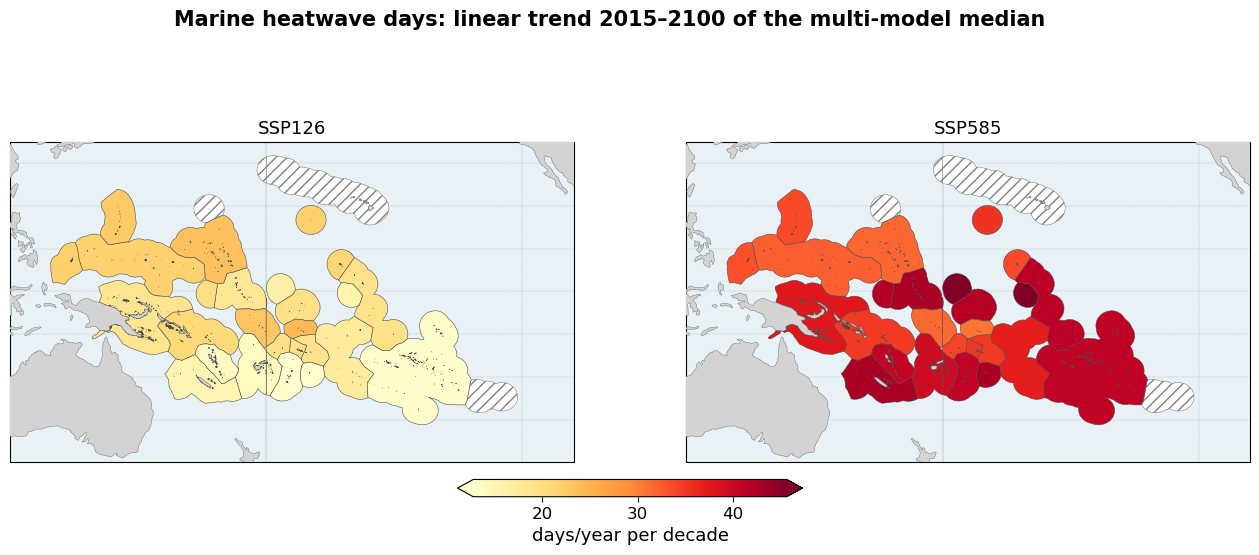

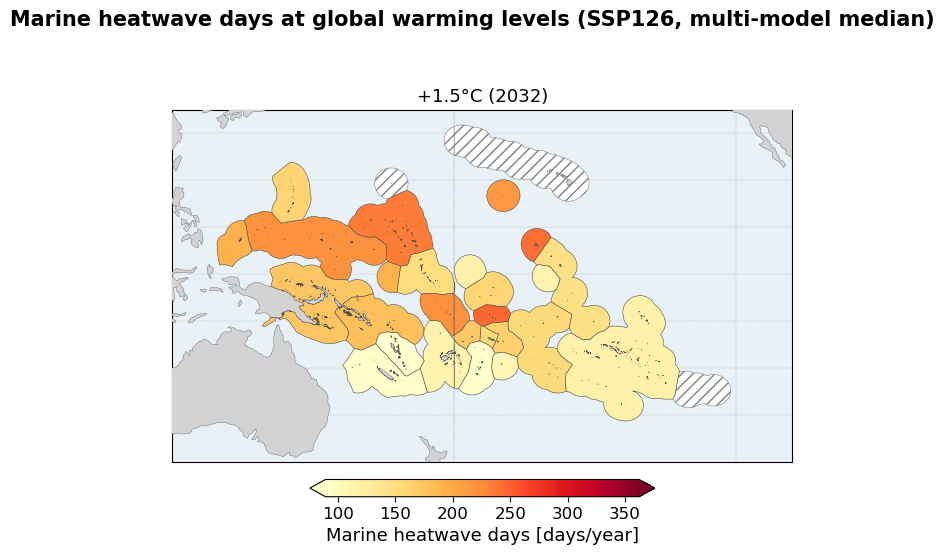

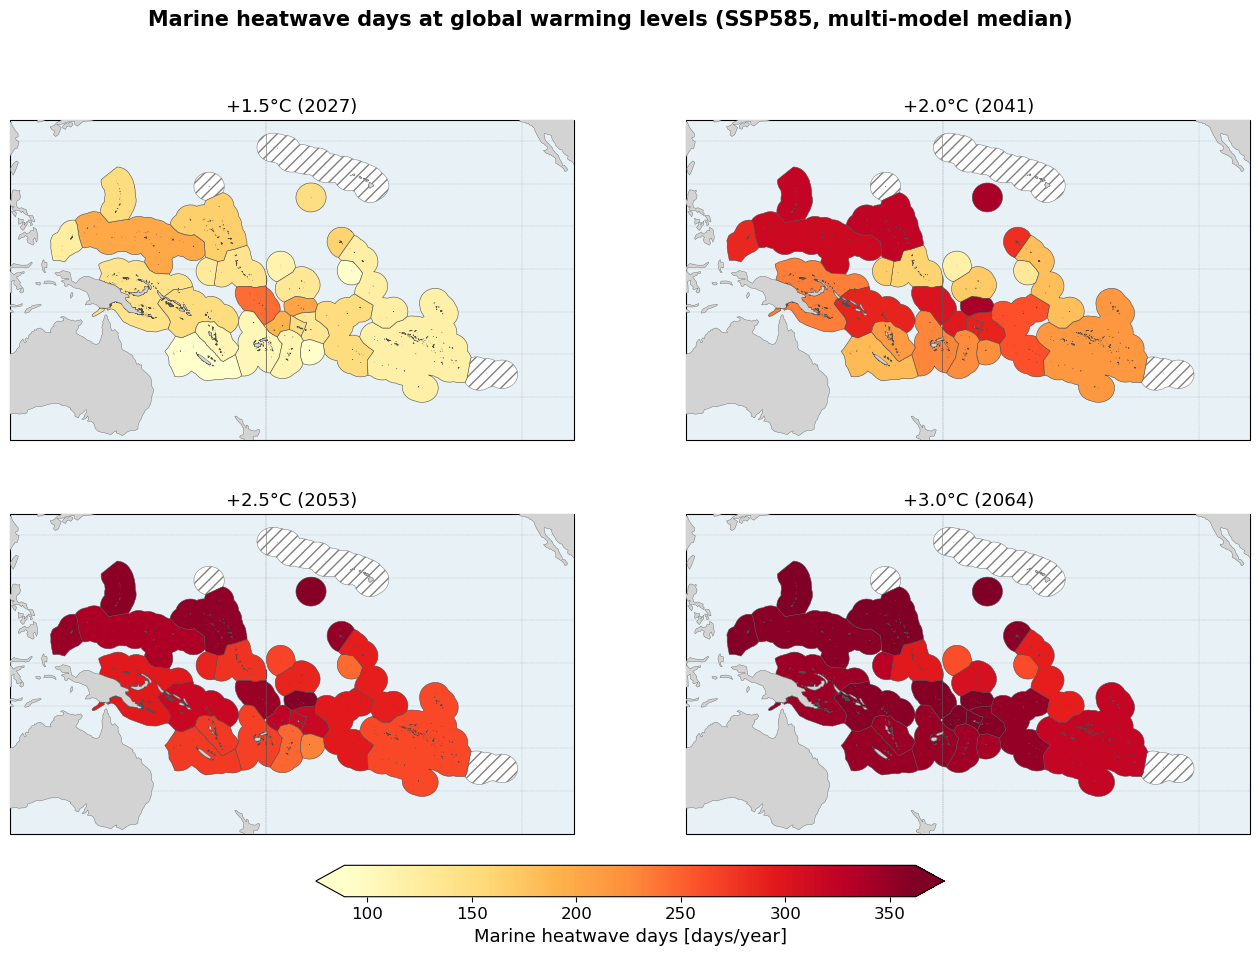

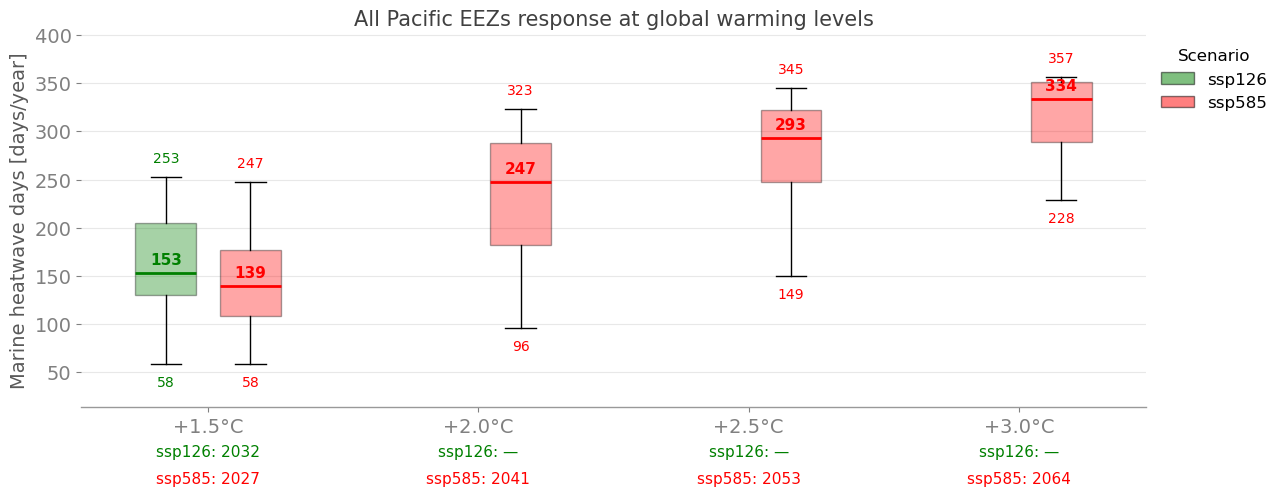

In [4]:
ds_mhw = reg.extract_mhw_regional(eez, ssp_scenarios)
figs, tables = reg.indicator_report(ds_mhw, "mhw_days", scenario_info, eez, ssp_scenarios, map_scenario,
                                    fig_dir, tables_dir, absolute=True)
glue("mhw_fig", figs["levels"], display=False)
reg.show_tables(tables)
